# Day 3 — SVM, Naive Bayes and Clustering
**System 7 · Week 3 · Commit: `day-17-svm-clustering`**

**Module B:** SVM, Naive Bayes, K-Means, hierarchical clustering, DBSCAN.

**Practice questions solved today:** Q9, Q10 · **Learning topic:** Choosing *k* in K-Means (and when DBSCAN is better)

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, json, warnings
from sklearn.datasets import load_breast_cancer, make_moons, make_circles
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (precision_score, recall_score, f1_score, accuracy_score, confusion_matrix,
                             ConfusionMatrixDisplay, silhouette_score, adjusted_rand_score)
from scipy.cluster.hierarchy import dendrogram, linkage
warnings.filterwarnings("ignore")
RANDOM_STATE = 42
R = {}

def plot_boundary(model, X, y, ax, title):
    xx, yy = np.meshgrid(np.linspace(X[:, 0].min()-.5, X[:, 0].max()+.5, 300), np.linspace(X[:, 1].min()-.5, X[:, 1].max()+.5, 300))
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=.25, cmap="coolwarm"); ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolor="k", s=18); ax.set_title(title)

## Part 1 — Support Vector Machines (SVM)
An SVM finds the boundary with the **widest margin** between classes; only the closest points (*support vectors*) define it.
The **kernel** lets it draw curved boundaries (`rbf`, `poly`), `C` controls how strictly it punishes misclassified points (large C = tighter fit, risk of overfitting) and `gamma` (RBF) controls how far one point's influence reaches.

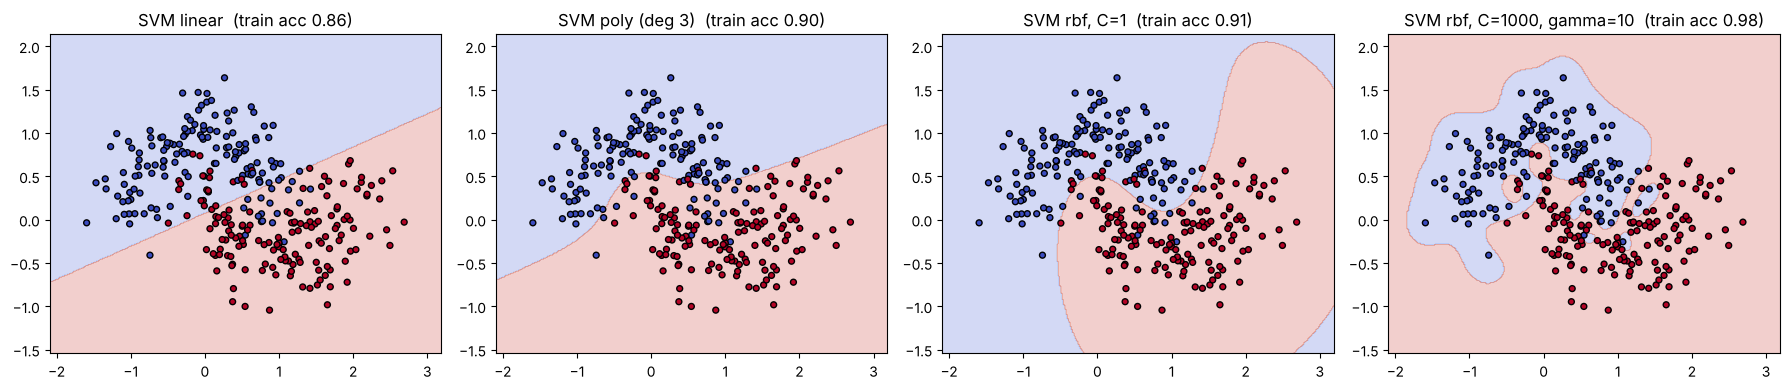

In [2]:
Xm, ym = make_moons(n_samples=300, noise=.25, random_state=RANDOM_STATE)
fig, ax = plt.subplots(1, 4, figsize=(18, 4))
for a, (k, kw) in zip(ax, [("linear", {}), ("poly (deg 3)", dict(kernel="poly", degree=3)), ("rbf, C=1", dict(kernel="rbf", C=1)), ("rbf, C=1000, gamma=10", dict(kernel="rbf", C=1000, gamma=10))]):
    kw.setdefault("kernel", "linear"); m = SVC(**kw).fit(Xm, ym); plot_boundary(m, Xm, ym, a, f"SVM {k}  (train acc {m.score(Xm, ym):.2f})")
plt.tight_layout(); plt.show()

The linear kernel cannot bend around the moons; RBF can. The last panel (huge `C` and `gamma`) wraps around individual points — a classic **overfit** boundary.

## Part 2 — Naive Bayes
Naive Bayes applies Bayes' rule, *P(class | features) ∝ P(class) × ΠP(feature | class)*, and **naively assumes features are independent**. For numeric features `GaussianNB` models each feature per class as a normal distribution.
It is extremely fast, works with little data, and is a strong baseline — but correlated features break the independence assumption.

## Q10 (Medium) — Naive Bayes vs SVM on the same data: precision and recall
Dataset: breast cancer. I flip the labels so that **malignant = 1 (positive class)**, which makes precision/recall read naturally.

             Precision  Recall      F1  Accuracy
Model                                           
Naive Bayes     0.9231  0.8571  0.8889    0.9211
SVM (RBF)       1.0000  0.9286  0.9630    0.9737


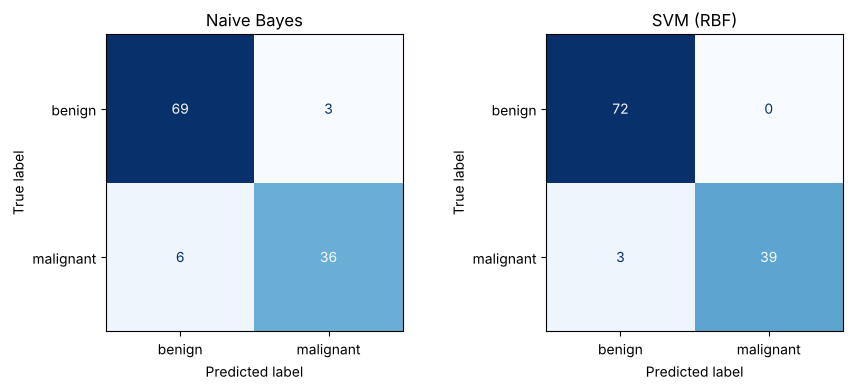

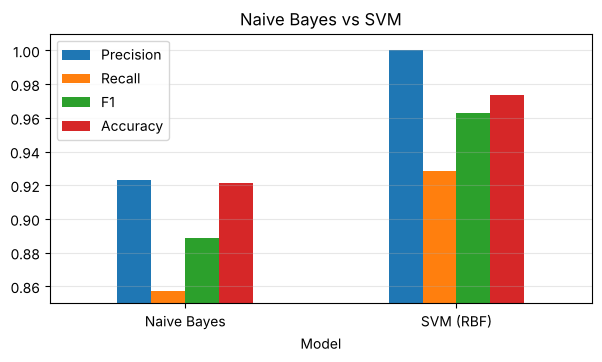

In [3]:
bc = load_breast_cancer(); Xb = bc.data; yb = 1 - bc.target           # 1 = malignant
Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(Xb, yb, test_size=.2, stratify=yb, random_state=RANDOM_STATE)
nb  = make_pipeline(StandardScaler(), GaussianNB()).fit(Xb_tr, yb_tr)
svm = make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1, random_state=RANDOM_STATE)).fit(Xb_tr, yb_tr)

rows = []
for name, m in [("Naive Bayes", nb), ("SVM (RBF)", svm)]:
    p = m.predict(Xb_te)
    rows.append([name, precision_score(yb_te, p), recall_score(yb_te, p), f1_score(yb_te, p), accuracy_score(yb_te, p)])
cmp = pd.DataFrame(rows, columns=["Model", "Precision", "Recall", "F1", "Accuracy"]).set_index("Model").round(4)
print(cmp)
R["q10"] = cmp.to_dict("index")

fig, ax = plt.subplots(1, 2, figsize=(9, 4))
for a, (name, m) in zip(ax, [("Naive Bayes", nb), ("SVM (RBF)", svm)]):
    ConfusionMatrixDisplay.from_predictions(yb_te, m.predict(Xb_te), display_labels=["benign", "malignant"], cmap="Blues", ax=a, colorbar=False); a.set_title(name)
plt.tight_layout(); plt.show()
cmp.plot.bar(figsize=(7, 3.5), rot=0); plt.ylim(.85, 1.01); plt.title("Naive Bayes vs SVM"); plt.grid(axis="y", alpha=.3); plt.show()

In [4]:
better_p = cmp.Precision.idxmax(); better_r = cmp.Recall.idxmax()
print(f"Higher precision: {better_p} ({cmp.Precision.max():.3f}) | Higher recall: {better_r} ({cmp.Recall.max():.3f})")
print("Interpretation: precision = how many predicted-malignant are truly malignant; recall = how many true malignant tumours were caught.")
print("For cancer screening we prefer the model with the higher RECALL (fewer missed cases), as long as precision is still acceptable.")

Higher precision: SVM (RBF) (1.000) | Higher recall: SVM (RBF) (0.929)
Interpretation: precision = how many predicted-malignant are truly malignant; recall = how many true malignant tumours were caught.
For cancer screening we prefer the model with the higher RECALL (fewer missed cases), as long as precision is still acceptable.


## Part 3 — Clustering: customer data
Clustering is **unsupervised**: there is no target column, the algorithm groups similar rows. I generate a reproducible *mall-customers* dataset (500 customers, 5 hidden lifestyle groups) and save it as `customers.csv`.

In [5]:
rng = np.random.default_rng(RANDOM_STATE)
groups = [  # (n, age, income k$, spending score)
    (110, 25, 30, 75), (100, 45, 85, 20), (100, 30, 90, 85), (100, 55, 35, 25), (90, 35, 55, 50)]
parts = []
for n, a, inc, sp in groups:
    parts.append(pd.DataFrame({"age": rng.normal(a, 4, n), "annual_income_k": rng.normal(inc, 7, n), "spending_score": rng.normal(sp, 8, n)}))
cust = pd.concat(parts, ignore_index=True).sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)
cust["age"] = cust.age.clip(18, 70).round(); cust["annual_income_k"] = cust.annual_income_k.clip(10, 140).round(1); cust["spending_score"] = cust.spending_score.clip(1, 100).round()
cust.insert(0, "customer_id", range(1, len(cust)+1)); cust.to_csv("customers.csv", index=False)
print(cust.shape); display(cust.head())
feat = ["age", "annual_income_k", "spending_score"]
scaler_c = StandardScaler().fit(cust[feat]); Xc = scaler_c.transform(cust[feat])      # distance-based -> scaling is essential

(500, 4)


,customer_id,age,annual_income_k,spending_score
0,1,49.0,33.9,32.0
1,2,27.0,37.7,54.0
2,3,55.0,30.4,40.0
3,4,54.0,82.6,8.0
4,5,21.0,27.7,90.0


## Q9 (Medium) — K-Means for k = 2…10: elbow curve + silhouette score
* **Inertia** (within-cluster sum of squares) always falls as k grows → look for the **elbow** where the improvement flattens.
* **Silhouette score** (−1…1) measures how well each point fits its own cluster compared with the nearest other one → pick the k where it is **highest**.

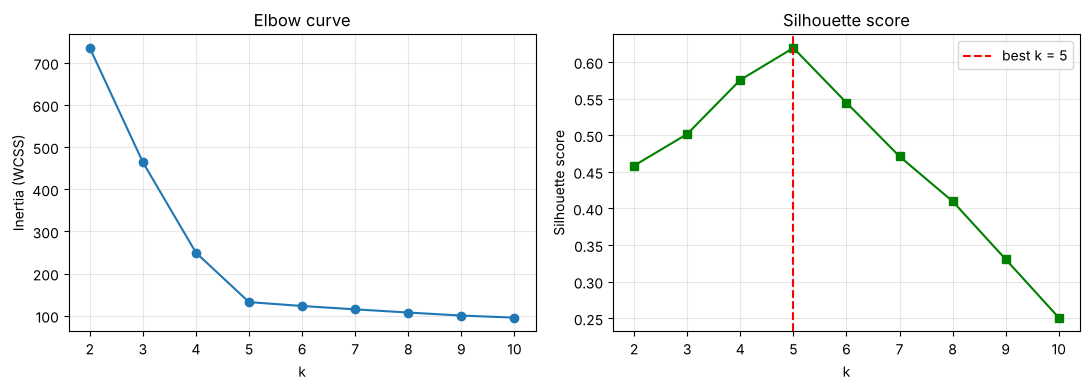

 k  inertia  silhouette
 2    735.5      0.4585
 3    464.2      0.5017
 4    249.6      0.5755
 5    132.4      0.6192
 6    123.2      0.5445
 7    115.3      0.4711
 8    107.7      0.4098
 9    100.5      0.3306
10     95.6      0.2510

=> Highest silhouette at k = 5 (silhouette = 0.619); the elbow also bends around that value.


In [6]:
ks = range(2, 11); inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Xc)
    inertia.append(km.inertia_); sil.append(silhouette_score(Xc, km.labels_))
best_k = list(ks)[int(np.argmax(sil))]

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ks, inertia, "o-"); ax[0].set(xlabel="k", ylabel="Inertia (WCSS)", title="Elbow curve"); ax[0].grid(alpha=.3)
ax[1].plot(ks, sil, "s-", color="g"); ax[1].axvline(best_k, ls="--", color="r", label=f"best k = {best_k}"); ax[1].set(xlabel="k", ylabel="Silhouette score", title="Silhouette score"); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()
print(pd.DataFrame({"k": list(ks), "inertia": np.round(inertia, 1), "silhouette": np.round(sil, 4)}).to_string(index=False))
print(f"\n=> Highest silhouette at k = {best_k} (silhouette = {max(sil):.3f}); the elbow also bends around that value.")
R["q9"] = {"best_k": best_k, "best_silhouette": round(max(sil), 4)}

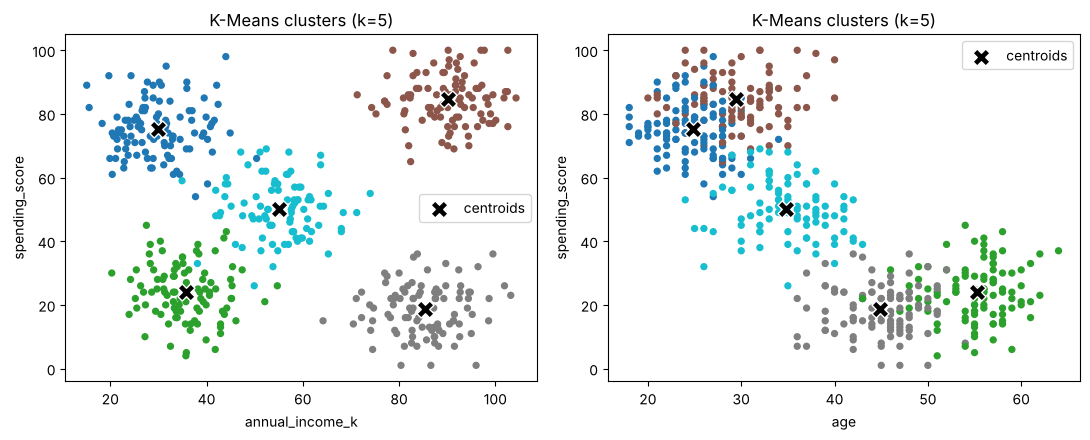

,age,annual_income_k,spending_score,size
cluster,,,,
0,24.8,29.9,75.3,110
1,55.2,35.7,24.0,99
2,29.4,90.2,84.6,100
3,44.9,85.3,18.6,100
4,34.8,55.1,50.1,91


In [7]:
km = KMeans(n_clusters=best_k, n_init=10, random_state=RANDOM_STATE).fit(Xc); cust["cluster"] = km.labels_
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for a, (x, y) in zip(ax, [("annual_income_k", "spending_score"), ("age", "spending_score")]):
    sc = a.scatter(cust[x], cust[y], c=cust.cluster, cmap="tab10", s=18); a.set(xlabel=x, ylabel=y, title=f"K-Means clusters (k={best_k})")
    cent = scaler_c.inverse_transform(km.cluster_centers_)      # back to original units
    a.scatter(cent[:, feat.index(x)], cent[:, feat.index(y)], c="k", marker="X", s=150, edgecolor="w", label="centroids"); a.legend()
plt.tight_layout(); plt.show()
cust.groupby("cluster")[feat].mean().round(1).assign(size=cust.cluster.value_counts().sort_index())

## Part 4 — Hierarchical clustering
Agglomerative clustering starts with every point alone and repeatedly merges the two closest clusters (here with **Ward** linkage). The **dendrogram** shows the merge order; cutting it at a height gives a chosen number of clusters. Unlike K-Means, you do not need to fix *k* up front.

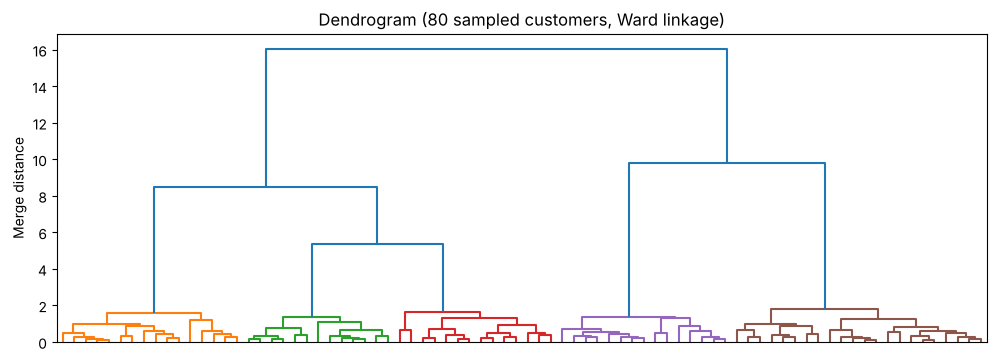

Agreement between K-Means and Hierarchical labels (Adjusted Rand Index): 0.985  (1.0 = identical grouping)


In [8]:
sample = np.random.default_rng(RANDOM_STATE).choice(len(Xc), 80, replace=False)
Z = linkage(Xc[sample], method="ward")
plt.figure(figsize=(12, 4)); dendrogram(Z, no_labels=True, color_threshold=Z[-4, 2]); plt.title("Dendrogram (80 sampled customers, Ward linkage)"); plt.ylabel("Merge distance"); plt.show()

agg = AgglomerativeClustering(n_clusters=best_k, linkage="ward").fit(Xc)
ari = adjusted_rand_score(km.labels_, agg.labels_)
print(f"Agreement between K-Means and Hierarchical labels (Adjusted Rand Index): {ari:.3f}  (1.0 = identical grouping)")
R["hier_ari"] = round(ari, 3)

## Part 5 — DBSCAN (density-based clustering) and when it beats K-Means
DBSCAN groups points that are densely packed: `eps` is the neighbourhood radius and `min_samples` the points needed to form a dense core. It
* finds **arbitrarily shaped** clusters,
* needs **no k**,
* labels sparse points as **noise (−1)**.

K-Means, by contrast, assumes round, similar-sized clusters. Compare them on two moons:

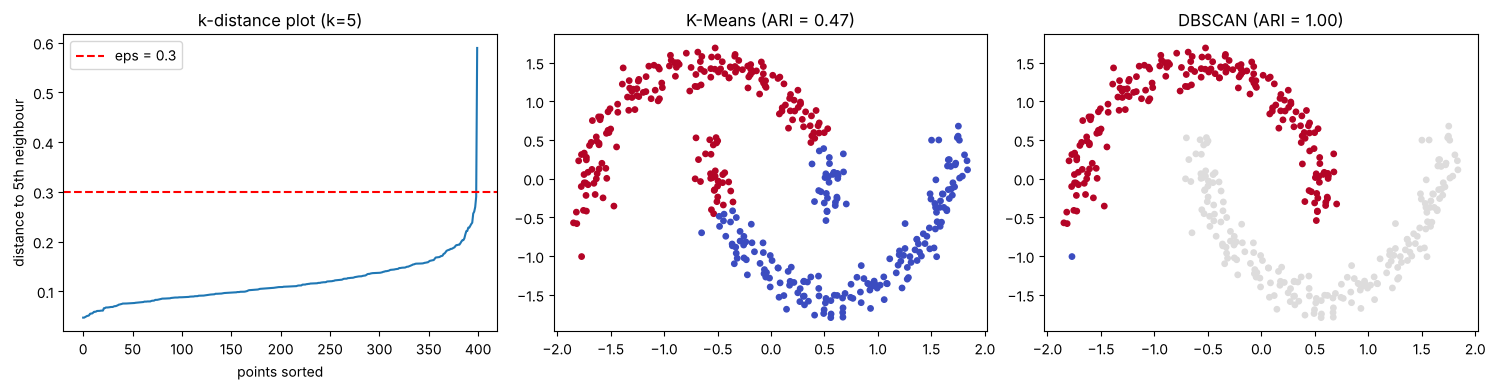

{'kmeans_ari': 0.475, 'dbscan_ari': 0.995, 'noise_points': 1}


In [9]:
Xmo, ymo = make_moons(n_samples=400, noise=.07, random_state=RANDOM_STATE); Xmo = StandardScaler().fit_transform(Xmo)

# choose eps with a k-distance plot (look for the "knee")
d = np.sort(NearestNeighbors(n_neighbors=5).fit(Xmo).kneighbors(Xmo)[0][:, -1])
km_m = KMeans(2, n_init=10, random_state=RANDOM_STATE).fit(Xmo); db = DBSCAN(eps=.3, min_samples=5).fit(Xmo)

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(d); ax[0].axhline(.3, color="r", ls="--", label="eps = 0.3"); ax[0].set(title="k-distance plot (k=5)", xlabel="points sorted", ylabel="distance to 5th neighbour"); ax[0].legend()
ax[1].scatter(*Xmo.T, c=km_m.labels_, cmap="coolwarm", s=15); ax[1].set_title(f"K-Means (ARI = {adjusted_rand_score(ymo, km_m.labels_):.2f})")
ax[2].scatter(*Xmo.T, c=db.labels_, cmap="coolwarm", s=15); ax[2].set_title(f"DBSCAN (ARI = {adjusted_rand_score(ymo, db.labels_):.2f})")
plt.tight_layout(); plt.show()
R["dbscan"] = {"kmeans_ari": round(adjusted_rand_score(ymo, km_m.labels_), 3), "dbscan_ari": round(adjusted_rand_score(ymo, db.labels_), 3), "noise_points": int((db.labels_ == -1).sum())}
print(R["dbscan"])

## Learning topic — Choosing *k* in K-Means, and when DBSCAN is better
* **Elbow method:** plot inertia against k and pick the point where adding clusters stops helping much. It can be ambiguous when the curve is smooth.
* **Silhouette score:** pick the k with the highest average silhouette; it is a more objective tie-breaker. Combine both with common sense about what the business can act on (e.g. 5 customer segments is manageable, 15 is not).
* **Use DBSCAN instead when** clusters are non-spherical (moons, rings), when the data contains **outliers/noise** you want to flag rather than force into a cluster, or when you do not know the number of clusters. Its weaknesses: sensitive to `eps`, and it struggles when clusters have very different densities.

### Summary of Day 3
| Algorithm | Needs k? | Cluster shape | Handles noise |
|---|---|---|---|
| K-Means | Yes | round/similar size | No |
| Hierarchical | No (cut dendrogram) | flexible, slower on big data | No |
| DBSCAN | No (needs `eps`) | any shape | Yes (label −1) |

In [10]:
json.dump(R, open("results.json", "w"), indent=2, default=float); print("results.json saved")

results.json saved
